In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 


df = pd.read_csv("player_summary.csv")

In [2]:
df.head()

,player,phase,matches,bat_innings,bat_balls,bat_runs,bat_outs,bat_avg,bat_sr,bat_4s,bat_6s,bat_runs_above_avg,bowl_balls,bowl_wkts,bowl_avg,bowl_runs,bowl_economy,bowl_4fers,bowl_5fers
0,A Adey,Mid,1,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.00,18.0,1.0,34.0,34.0,11.33,0.0,0.0
1,A Balbirnie,Opening,42,42.0,524.0,768.0,17.0,45.18,146.56,102.0,23.0,102.27,0.0,0.0,NaN,0.0,NaN,0.0,0.0
2,A Balbirnie,Mid,24,24.0,331.0,485.0,18.0,26.94,146.53,53.0,15.0,68.77,0.0,0.0,NaN,0.0,NaN,0.0,0.0
3,A Balbirnie,Death,4,4.0,25.0,61.0,2.0,30.50,244.00,3.0,6.0,24.38,0.0,0.0,NaN,0.0,NaN,0.0,0.0
4,A Cawley,Opening,10,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.00,114.0,4.0,32.0,128.0,6.74,0.0,0.0


In [3]:
df.columns

Index(['player', 'phase', 'matches', 'bat_innings', 'bat_balls', 'bat_runs',
       'bat_outs', 'bat_avg', 'bat_sr', 'bat_4s', 'bat_6s',
       'bat_runs_above_avg', 'bowl_balls', 'bowl_wkts', 'bowl_avg',
       'bowl_runs', 'bowl_economy', 'bowl_4fers', 'bowl_5fers'],
      dtype='str')

In [4]:
# Selecting feature for visualization 

batting_feature = ['bat_innings', 'bat_balls', 'bat_runs',
       'bat_outs', 'bat_avg', 'bat_sr']

bowling_feature = ['bowl_balls', 'bowl_wkts', 'bowl_avg',
       'bowl_runs', 'bowl_economy']


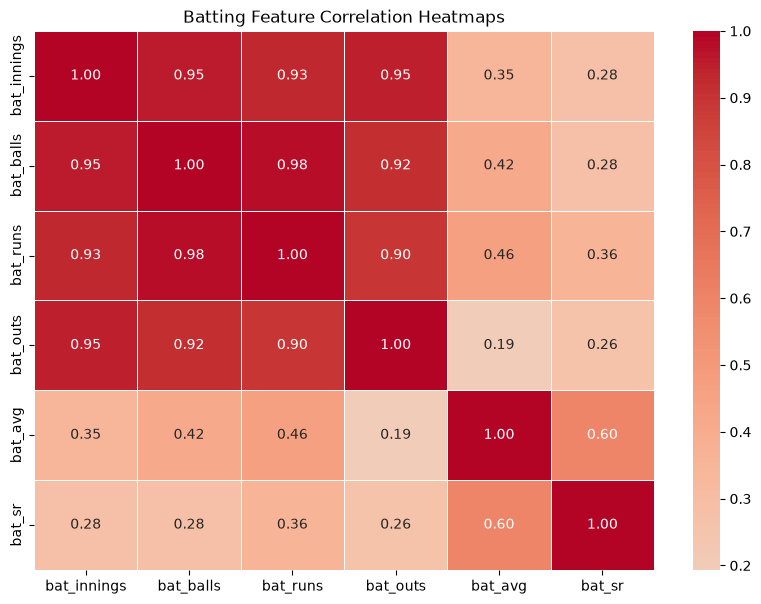

In [6]:
# Correlation Heatmaps 

# Objective : Understanding the batting and bowling features have relationship with each other 

# A. Correlation heatmaps of batting features 

bats_corr = df[batting_feature].corr()

plt.figure(figsize = (10,7))

sns.heatmap(
    bats_corr,
    annot=True,
    cmap = 'coolwarm',
    fmt = '.2f',
    center = 0,
    linewidth = 0.5
)

plt.title("Batting Feature Correlation Heatmaps")
plt.show()


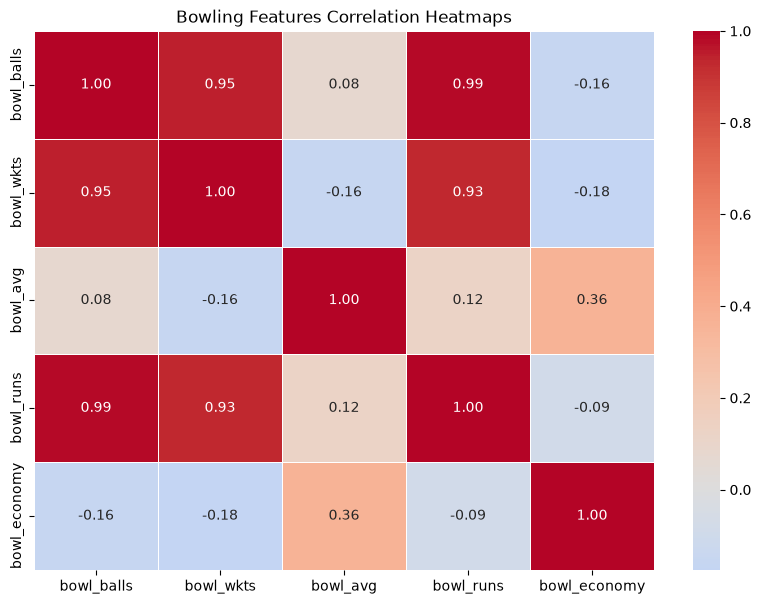

In [9]:
# B. Correlation heatmaps of bowling features 

bowl_corr = df[bowling_feature].corr()

plt.figure(figsize = (10,7))

sns.heatmap(
    bowl_corr,
    annot = True,
    cmap = 'coolwarm',
    fmt = ".2f",
    center = 0,
    linewidth= 0.5 
)

plt.title("Bowling Features Correlation Heatmaps")
plt.show()

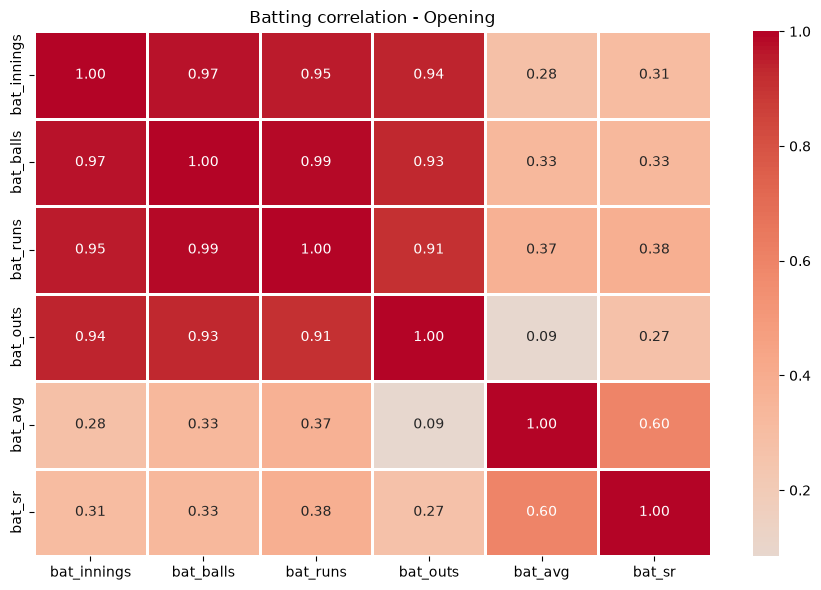

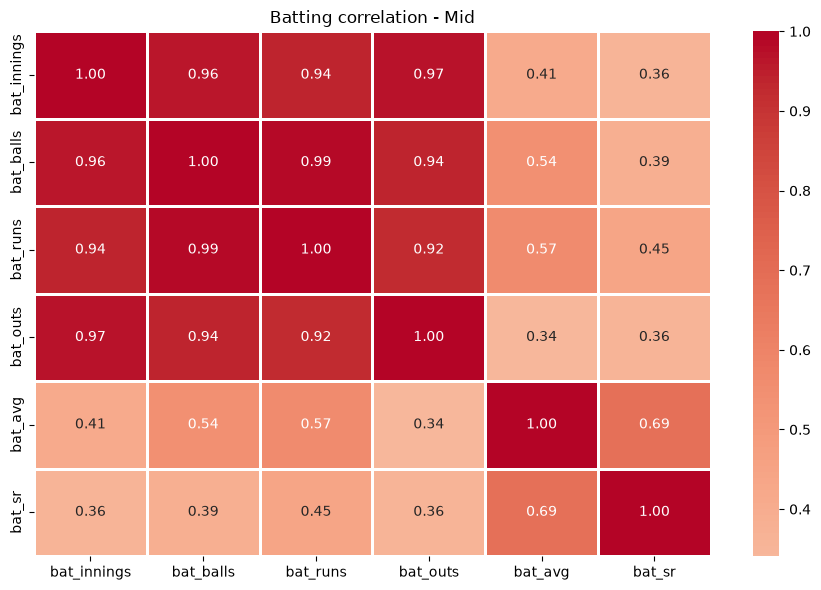

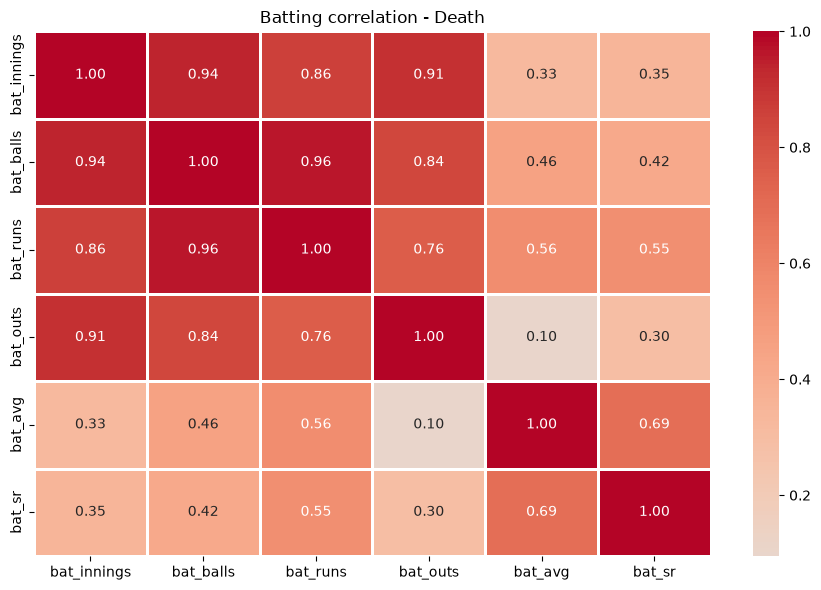

In [13]:
# C . Phase wise correaltion matrices 

phases = ['Opening' , 'Mid' , 'Death']

# Batting performance correlation heatmap across the phases
for phase in phases: 
    phase_data = df[df['phase']==phase]

    phase_corr = phase_data[batting_feature].corr()

    plt.figure(figsize=(9,6))

    sns.heatmap(
        phase_corr,
        cmap = 'coolwarm',
        annot = True,
        center = 0,
        fmt = ".2f",
        linewidth = "2"
    )

    plt.title(f"Batting correlation - {phase}")
    plt.tight_layout()
    plt.show()

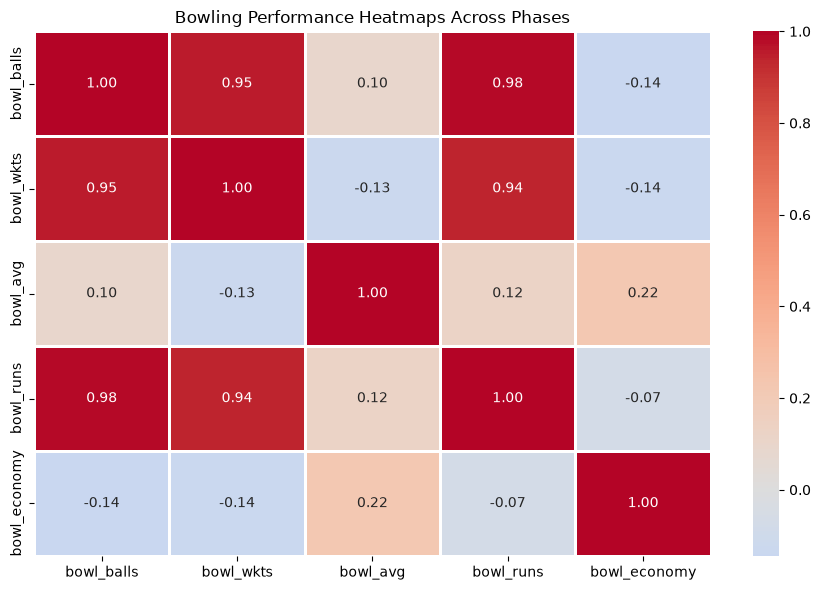

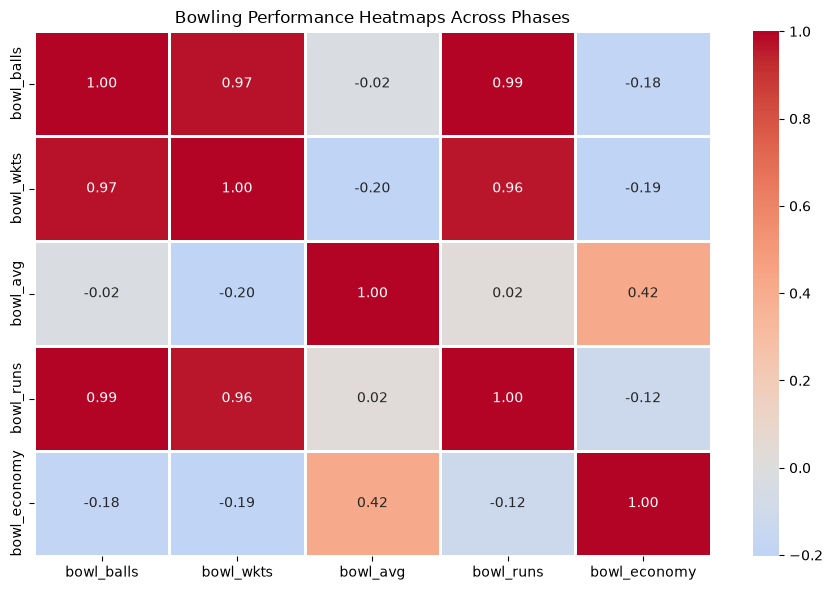

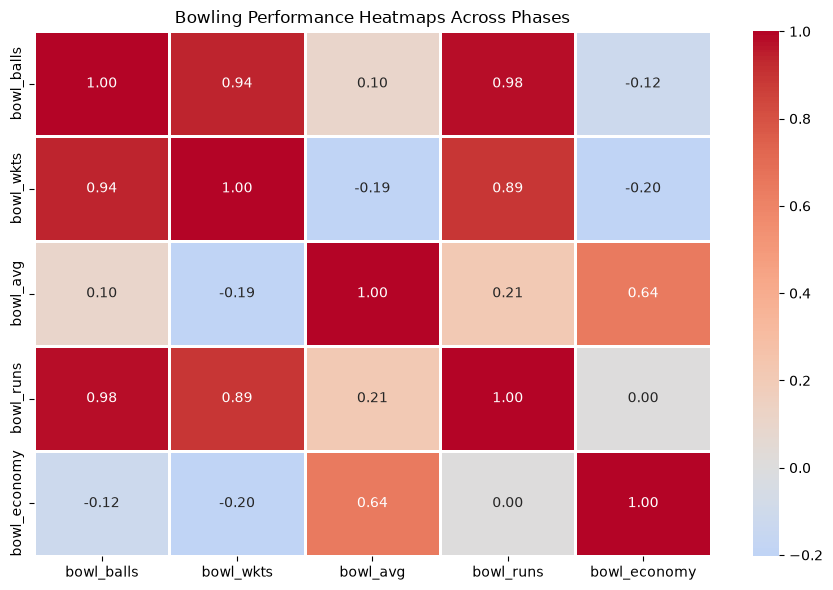

In [17]:
# Bowling performance correlation matrice across phase 

for phase in phases:
    phase_data = df[df['phase']==phase]

    phase_corr = phase_data[bowling_feature].corr()

    plt.figure(figsize = (9,6))
    sns.heatmap(
        phase_corr,
        annot=True,
        cmap = 'coolwarm',
        fmt = '.2f',
        center = 0,
        linewidth = "2"
    )

    plt.title("Bowling Performance Heatmaps Across Phases")
    plt.tight_layout()
    plt.show()


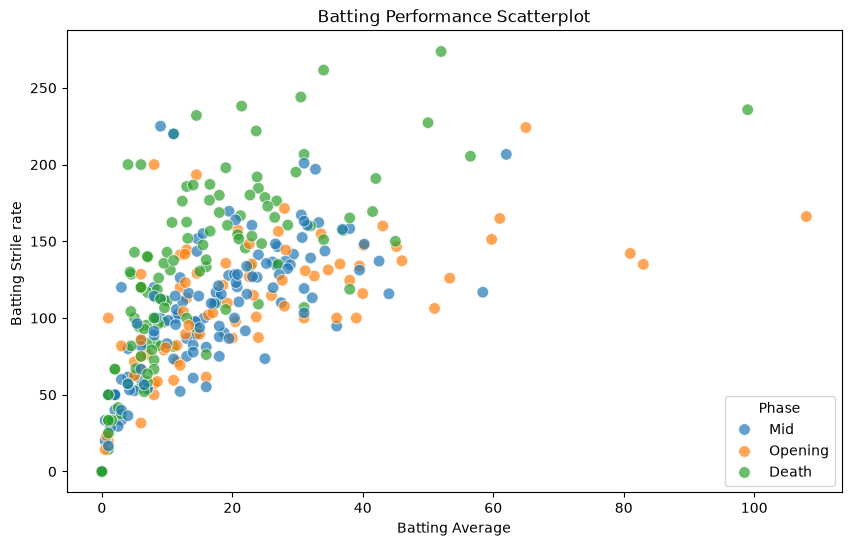

In [19]:
# Now according to heatmap correlation we identify the features which is highly correlated 

# Scatterplot 

# Objective : Visualize the relationship between two selected features and identify patterns 

# A. Batting Average vs strike rate 
plt.figure(figsize = (10,6))

sns.scatterplot(
    df,
    x=df['bat_avg'],
    y=df['bat_sr'],
    hue='phase',
    alpha = 0.7,
    s=70
)

plt.title("Batting Performance Scatterplot")
plt.xlabel("Batting Average")
plt.ylabel("Batting Strile rate ")
plt.legend(title= "Phase")
plt.show()

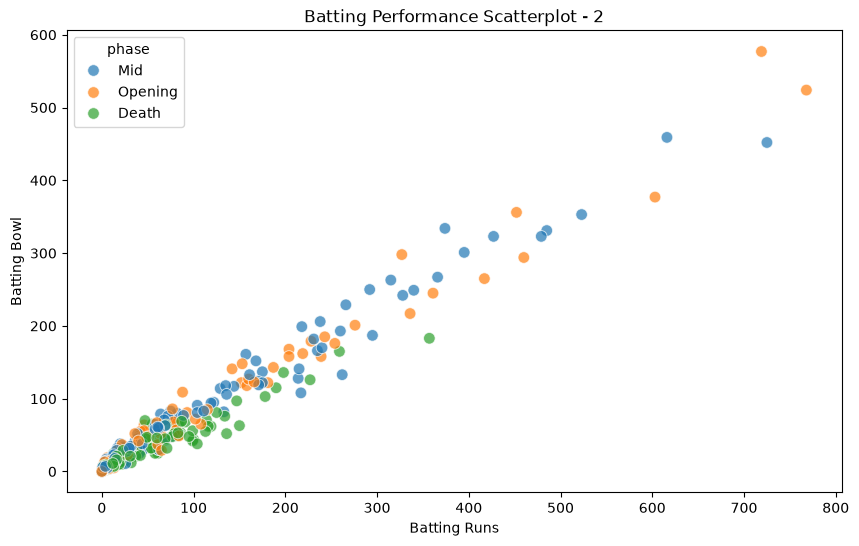

In [21]:
# B. Batting runs vs batting balls 

plt.figure(figsize = (10,6))

sns.scatterplot(
    df , 
    x = df['bat_runs'],
    y = df['bat_balls'],
    hue = 'phase',
    alpha = 0.7,
    s=70
)

plt.title("Batting Performance Scatterplot - 2")
plt.xlabel("Batting Runs")
plt.ylabel("Batting Bowl")
plt.legend(title = "phase")
plt.show()

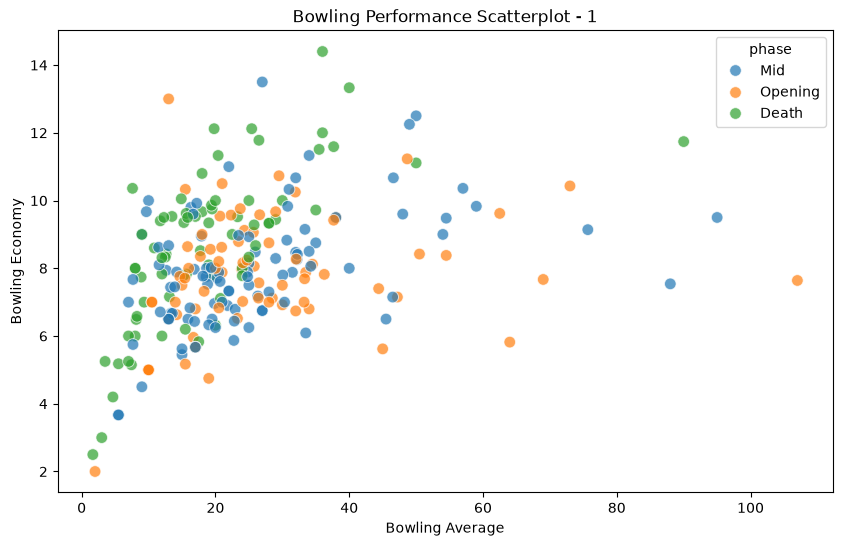

In [22]:
# C . Bowling Average vs Bowling Economy

plt.figure(figsize = (10,6))

sns.scatterplot(
    df,
    x = df['bowl_avg'],
    y = df['bowl_economy'],
    hue = 'phase',
    alpha = 0.7,
    s = 70
)

plt.title("Bowling Performance Scatterplot - 1")
plt.xlabel("Bowling Average")
plt.ylabel("Bowling Economy")
plt.legend(title = 'phase')
plt.show()


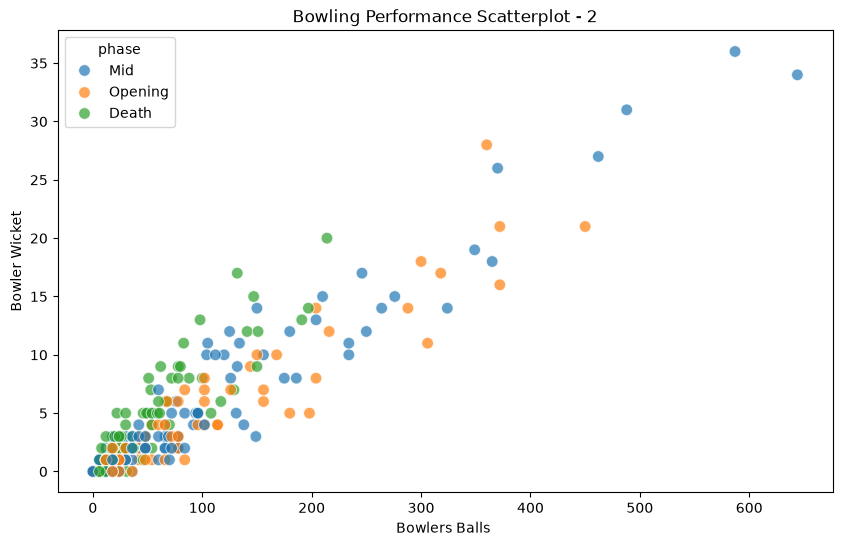

In [26]:
# D. Bowling wicket vs  total balls 

plt.figure(figsize = (10,6))

sns.scatterplot(
    df , 
    x = df['bowl_balls'],
    y = df['bowl_wkts'],
    hue= 'phase',
    alpha = 0.7,
    s = 70
)

plt.title("Bowling Performance Scatterplot - 2")
plt.xlabel("Bowlers Balls ")
plt.ylabel("Bowler Wicket")
plt.legend(title = "phase")
plt.show()

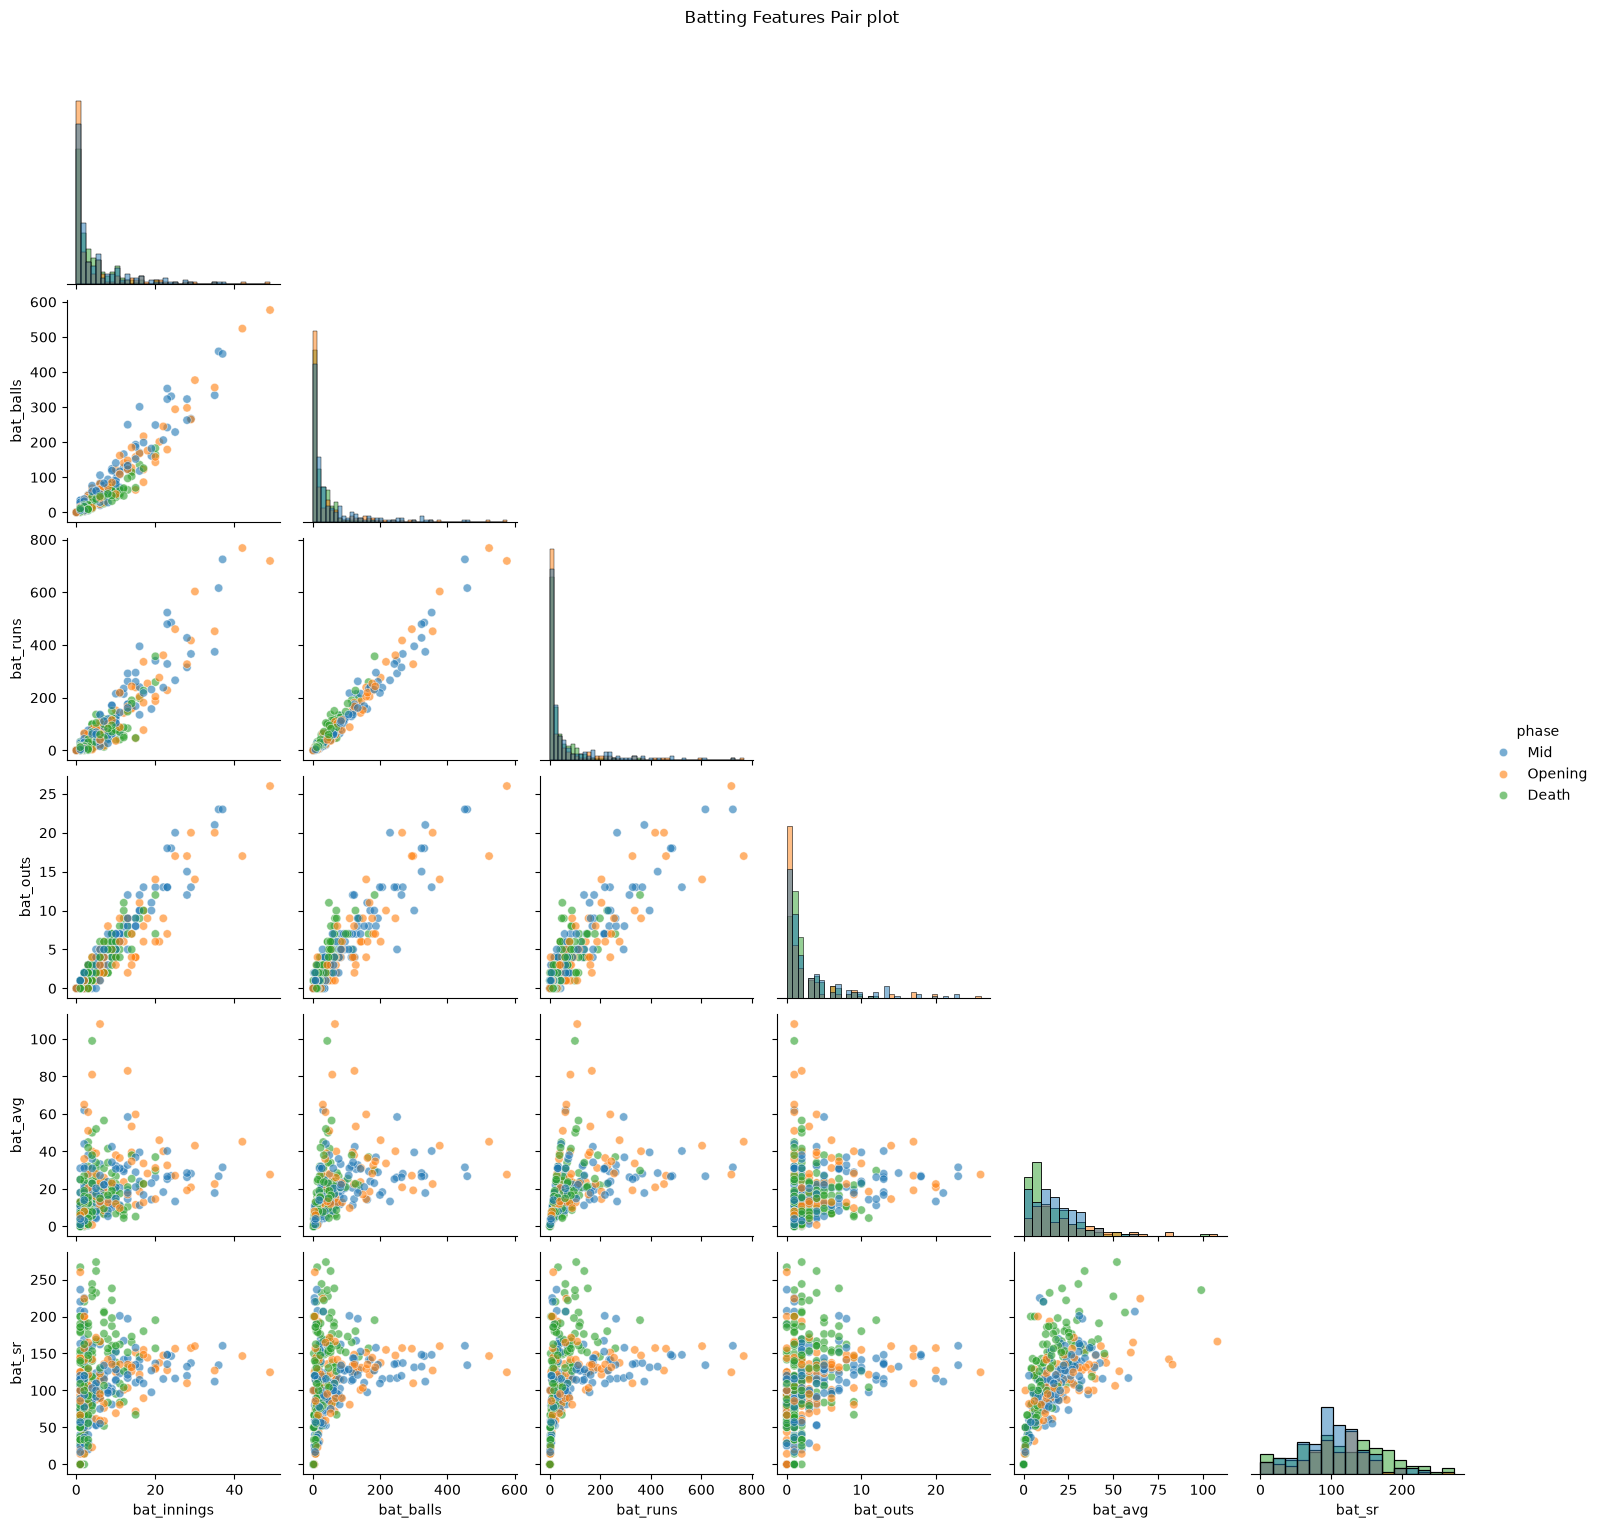

In [30]:
# Pairplot

# Objective : Understand relationship between multiple numerical features simulatenously 

# A . Batting Performance pairplot 

sns.pairplot(
    data = df,
    vars = batting_feature,
    hue = "phase",
    diag_kind = "hist",
    corner = True,
    plot_kws = {'alpha': 0.6}
    
)

plt.suptitle(
    'Batting Features Pair plot',
    y = 1.02
)

plt.show()

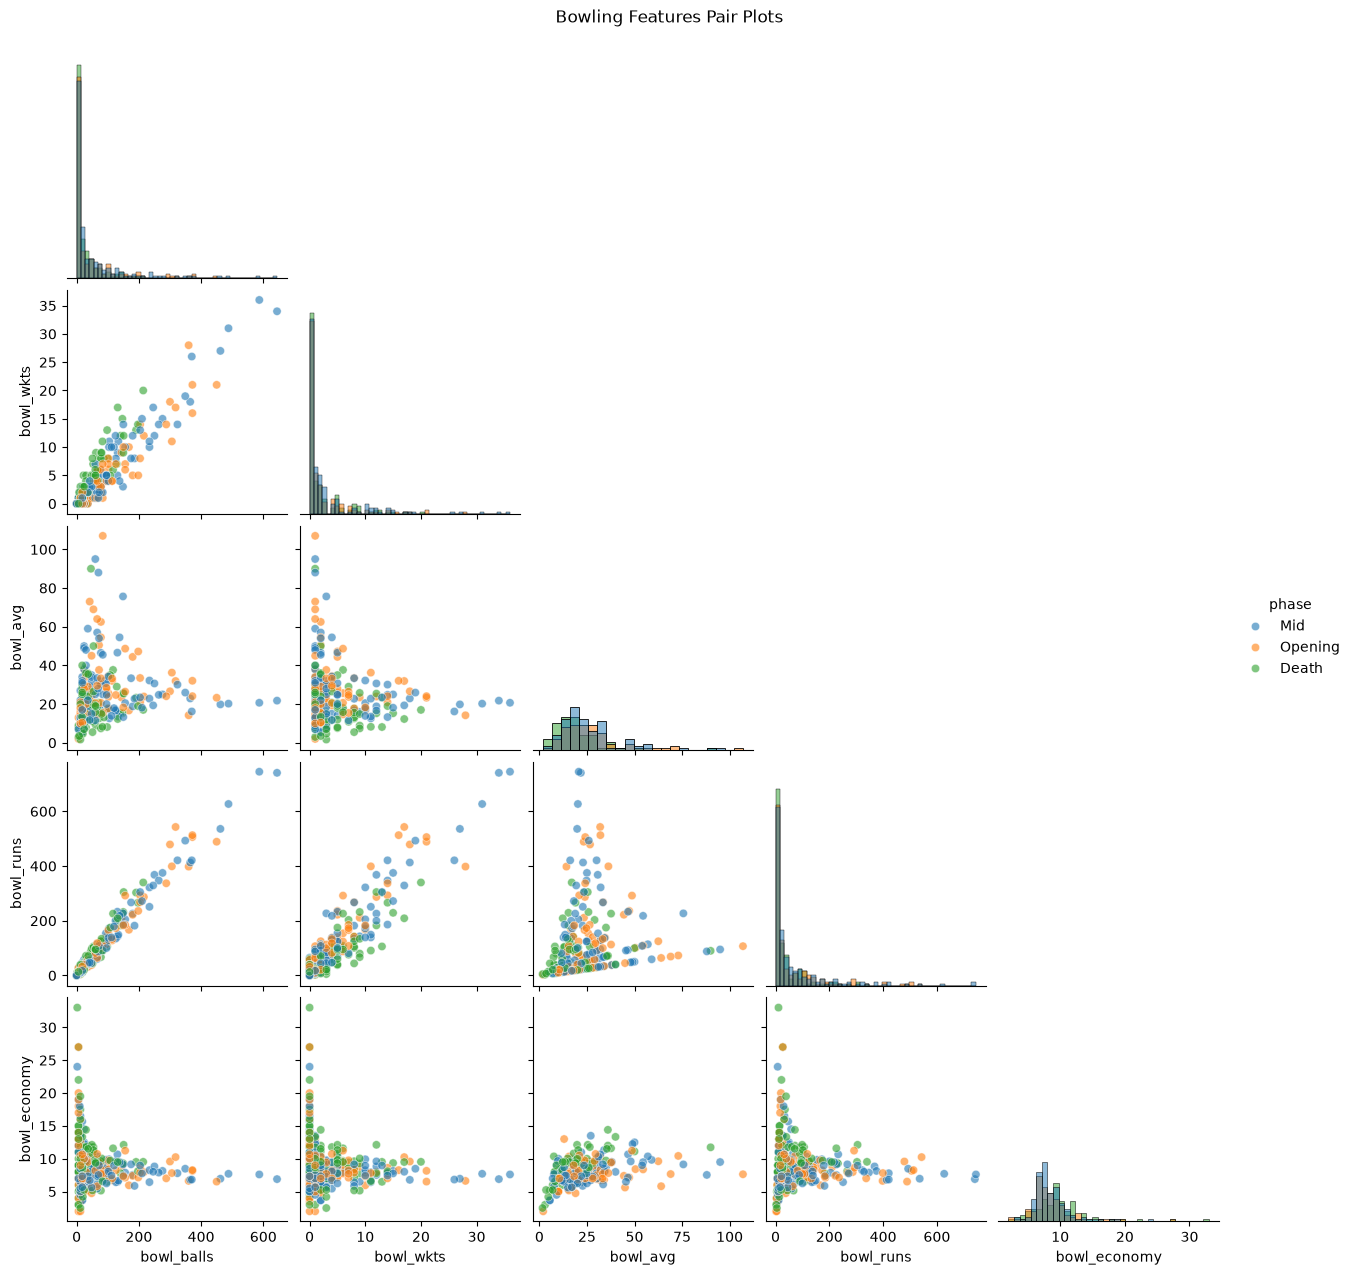

In [31]:
# B. Bowling Performance pairplot

sns.pairplot(
    data = df,
    vars = bowling_feature,
    hue = "phase",
    diag_kind = "hist",
    corner = True,
    plot_kws = {'alpha' : 0.6}
)

plt.suptitle(
    'Bowling Features Pair Plots',
    y = 1.02
)

plt.show()